In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing and recommendation engine
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

# Other utilities
import zipfile
import requests
import os
import difflib
import warnings

warnings.filterwarnings("ignore")

print("CineMatch libraries loaded successfully!")

CineMatch libraries loaded successfully!


In [2]:
# Official MovieLens dataset
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

response = requests.get(url)
response.raise_for_status()

with open("movies_dataset.zip", "wb") as file:
    file.write(response.content)

# Extract ZIP file
with zipfile.ZipFile("movies_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("data")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [3]:
movies = pd.read_csv("data/ml-latest-small/movies.csv")
ratings = pd.read_csv("data/ml-latest-small/ratings.csv")
tags = pd.read_csv("data/ml-latest-small/tags.csv")
links = pd.read_csv("data/ml-latest-small/links.csv")

print("Movies:", movies.shape)
print("Ratings:", ratings.shape)
print("Tags:", tags.shape)
print("Links:", links.shape)

display(movies.head())

Movies: (9742, 3)
Ratings: (100836, 4)
Tags: (3683, 4)
Links: (9742, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
print("Dataset Information")
print("-------------------")

print("Total Movies:", movies["movieId"].nunique())
print("Total Ratings:", len(ratings))
print("Total Users:", ratings["userId"].nunique())

print("\nMissing Values:")
print(movies.isnull().sum())

print("\nTop 10 Movie Genres:")

genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

display(genre_counts.head(10))

Dataset Information
-------------------
Total Movies: 9742
Total Ratings: 100836
Total Users: 610

Missing Values:
movieId    0
title      0
genres     0
dtype: int64

Top 10 Movie Genres:


,count
genres,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


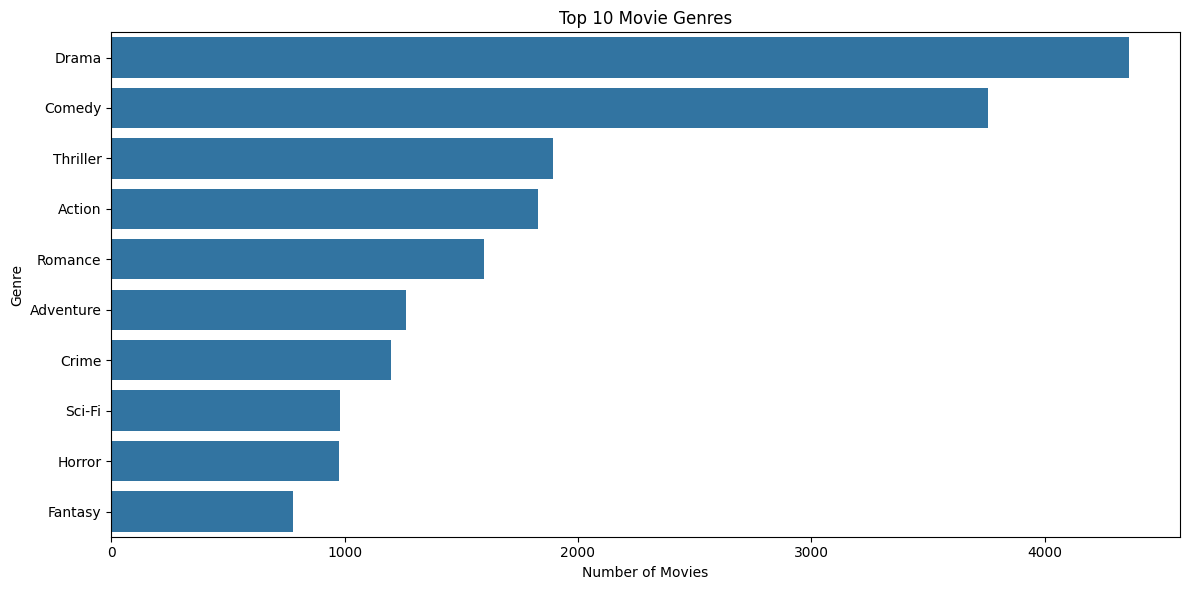

In [5]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.head(10).values,
    y=genre_counts.head(10).index
)

plt.title("Top 10 Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [6]:
rating_summary = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    total_ratings=("rating", "count")
).reset_index()

movie_analysis = movies.merge(
    rating_summary,
    on="movieId",
    how="left"
)

movie_analysis["average_rating"] = (
    movie_analysis["average_rating"].fillna(0)
)

movie_analysis["total_ratings"] = (
    movie_analysis["total_ratings"].fillna(0)
)

display(
    movie_analysis.sort_values(
        "total_ratings",
        ascending=False
    ).head(10)
)

,movieId,title,genres,average_rating,total_ratings
314,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164134,329.0
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429022,317.0
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197068,307.0
510,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.161290,279.0
1939,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192446,278.0
224,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231076,251.0
418,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,3.750000,238.0
97,110,Braveheart (1995),Action|Drama|War,4.031646,237.0
507,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,3.970982,224.0
461,527,Schindler's List (1993),Drama|War,4.225000,220.0


In [7]:
# Combine all tags belonging to each movie
tag_summary = (
    tags.groupby("movieId")["tag"]
    .apply(lambda x: " ".join(x.astype(str)))
    .reset_index()
)

tag_summary.columns = ["movieId", "movie_tags"]

# Merge tags into movie information
movie_data = movies.merge(
    tag_summary,
    on="movieId",
    how="left"
)

movie_data["movie_tags"] = (
    movie_data["movie_tags"].fillna("")
)

# Give genres more importance by repeating them
movie_data["combined_features"] = (
    movie_data["genres"].str.replace("|", " ", regex=False)
    + " "
    + movie_data["genres"].str.replace("|", " ", regex=False)
    + " "
    + movie_data["movie_tags"]
)

display(
    movie_data[
        ["title", "genres", "movie_tags", "combined_features"]
    ].head(10)
)

,title,genres,movie_tags,combined_features
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,pixar pixar fun,Adventure Animation Children Comedy Fantasy Ad...
1,Jumanji (1995),Adventure|Children|Fantasy,fantasy magic board game Robin Williams game,Adventure Children Fantasy Adventure Children ...
2,Grumpier Old Men (1995),Comedy|Romance,moldy old,Comedy Romance Comedy Romance moldy old
3,Waiting to Exhale (1995),Comedy|Drama|Romance,,Comedy Drama Romance Comedy Drama Romance
4,Father of the Bride Part II (1995),Comedy,pregnancy remake,Comedy Comedy pregnancy remake
5,Heat (1995),Action|Crime|Thriller,,Action Crime Thriller Action Crime Thriller
6,Sabrina (1995),Comedy|Romance,remake,Comedy Romance Comedy Romance remake
7,Tom and Huck (1995),Adventure|Children,,Adventure Children Adventure Children
8,Sudden Death (1995),Action,,Action Action
9,GoldenEye (1995),Action|Adventure|Thriller,,Action Adventure Thriller Action Adventure Thr...


In [8]:
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

tfidf_matrix = tfidf.fit_transform(
    movie_data["combined_features"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of movie features:", tfidf_matrix.shape[1])

TF-IDF matrix shape: (9742, 1572)
Number of movie features: 1572


In [9]:
# Map movie titles to their row positions
movie_indices = pd.Series(
    movie_data.index,
    index=movie_data["title"]
).drop_duplicates()


def recommend_movies(movie_name, number_of_recommendations=10):

    # Find matching movie title
    matches = difflib.get_close_matches(
        movie_name,
        movie_indices.index.tolist(),
        n=1,
        cutoff=0.4
    )

    if not matches:
        print("Movie not found. Try another title.")
        return None

    matched_title = matches[0]
    movie_index = movie_indices[matched_title]

    # Calculate similarity against all movies
    similarity_scores = linear_kernel(
        tfidf_matrix[movie_index],
        tfidf_matrix
    ).flatten()

    # Rank movies by similarity
    similar_indices = np.argsort(
        similarity_scores
    )[::-1]

    # Remove the selected movie itself
    similar_indices = [
        i for i in similar_indices
        if i != movie_index
    ]

    # Select top recommendations
    top_indices = similar_indices[
        :number_of_recommendations
    ]

    recommendations = movie_data.iloc[
        top_indices
    ][["title", "genres"]].copy()

    recommendations["similarity_score"] = [
        similarity_scores[i] for i in top_indices
    ]

    recommendations = recommendations.merge(
        rating_summary,
        on="movieId",
        how="left"
    ) if "movieId" in recommendations.columns else recommendations

    print(f"\nRecommendations for: {matched_title}")
    print("=" * 60)

    return recommendations.reset_index(drop=True)

In [10]:
recommendations = recommend_movies(
    "Interstellar",
    number_of_recommendations=10
)

display(recommendations)


Recommendations for: Interstellar (2014)


,title,genres,similarity_score
0,Primer (2004),Drama|Sci-Fi,0.612391
1,Stargate (1994),Action|Adventure|Sci-Fi,0.566402
2,Back to the Future (1985),Adventure|Comedy|Sci-Fi,0.547827
3,Bill & Ted's Excellent Adventure (1989),Adventure|Comedy|Sci-Fi,0.547827
4,Back to the Future Part II (1989),Adventure|Comedy|Sci-Fi,0.547827
5,Bill & Ted's Bogus Journey (1991),Adventure|Comedy|Fantasy|Sci-Fi,0.495223
6,Time Bandits (1981),Adventure|Comedy|Fantasy|Sci-Fi,0.495223
7,Star Trek (2009),Action|Adventure|Sci-Fi|IMAX,0.455657
8,The Butterfly Effect (2004),Drama|Sci-Fi|Thriller,0.442843
9,Edge of Tomorrow (2014),Action|Sci-Fi|IMAX,0.427804


In [11]:
recommend_movies("Inception", 10)


Recommendations for: Inception (2010)


,title,genres,similarity_score
0,Donnie Darko (2001),Drama|Mystery|Sci-Fi|Thriller,0.431771
1,Arrival (2016),Sci-Fi,0.426959
2,Watchmen (2009),Action|Drama|Mystery|Sci-Fi|Thriller|IMAX,0.411032
3,Strange Days (1995),Action|Crime|Drama|Mystery|Sci-Fi|Thriller,0.386709
4,Black Mirror: White Christmas (2014),Drama|Horror|Mystery|Sci-Fi|Thriller,0.380954
5,Super 8 (2011),Mystery|Sci-Fi|Thriller|IMAX,0.377103
6,Primal Fear (1996),Crime|Drama|Mystery|Thriller,0.353225
7,Gattaca (1997),Drama|Sci-Fi|Thriller,0.345385
8,Moon (2009),Drama|Mystery|Sci-Fi|Thriller,0.338294
9,Interstellar (2014),Sci-Fi|IMAX,0.338008


In [12]:
def recommend_movies(movie_name, number_of_recommendations=10):

    matches = difflib.get_close_matches(
        movie_name,
        movie_indices.index.tolist(),
        n=1,
        cutoff=0.4
    )

    if not matches:
        print("Movie not found. Try another title.")
        return None

    matched_title = matches[0]
    movie_index = movie_indices[matched_title]

    similarity_scores = linear_kernel(
        tfidf_matrix[movie_index],
        tfidf_matrix
    ).flatten()

    similar_indices = np.argsort(similarity_scores)[::-1]

    similar_indices = [
        i for i in similar_indices if i != movie_index
    ][:number_of_recommendations]

    recommendations = movie_data.iloc[
        similar_indices
    ][["movieId", "title", "genres"]].copy()

    recommendations["similarity_score"] = [
        similarity_scores[i] for i in similar_indices
    ]

    recommendations = recommendations.merge(
        rating_summary,
        on="movieId",
        how="left"
    )

    recommendations["average_rating"] = (
        recommendations["average_rating"].fillna(0)
    )

    recommendations["total_ratings"] = (
        recommendations["total_ratings"].fillna(0)
    )

    print(f"\nRecommendations for: {matched_title}")
    print("=" * 60)

    return recommendations.drop(
        columns=["movieId"]
    ).reset_index(drop=True)


Recommendations for: Interstellar (2014)


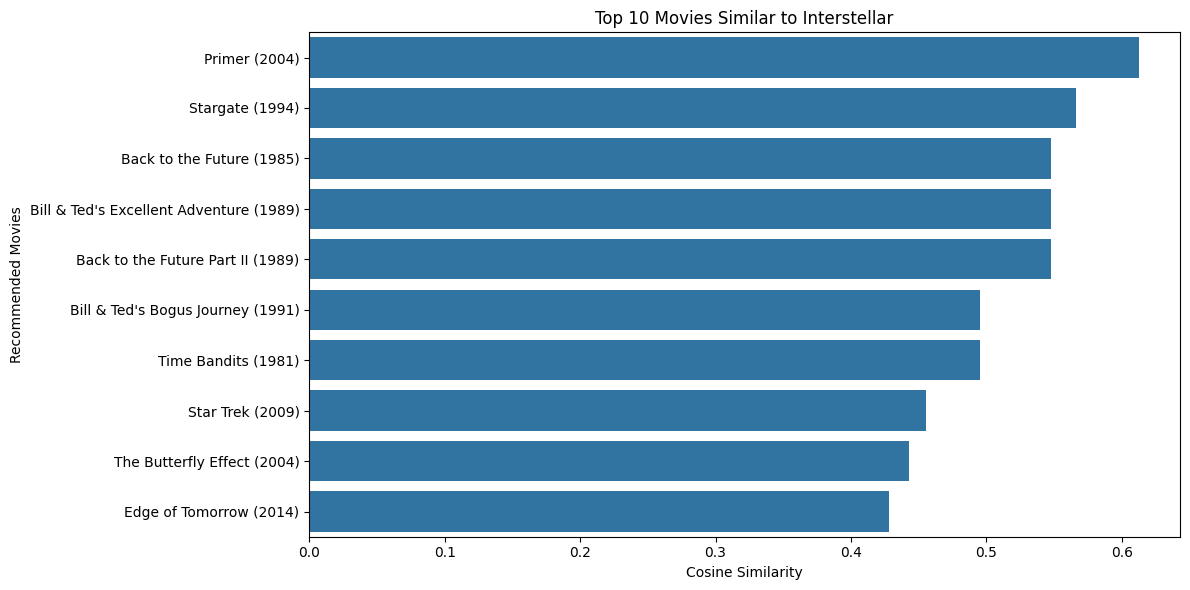

In [13]:
recommendations = recommend_movies("Interstellar", 10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=recommendations,
    x="similarity_score",
    y="title"
)

plt.title("Top 10 Movies Similar to Interstellar")
plt.xlabel("Cosine Similarity")
plt.ylabel("Recommended Movies")

plt.tight_layout()
plt.show()

In [14]:
test_movies = [
    "Interstellar",
    "Inception",
    "The Dark Knight",
    "Toy Story",
    "The Matrix"
]

for movie in test_movies:

    print("\n" + "=" * 70)

    result = recommend_movies(movie, 5)

    if result is not None:
        display(result)



Recommendations for: Interstellar (2014)


,title,genres,similarity_score,average_rating,total_ratings
0,Primer (2004),Drama|Sci-Fi,0.612391,3.794118,17
1,Stargate (1994),Action|Adventure|Sci-Fi,0.566402,3.375000,140
2,Back to the Future (1985),Adventure|Comedy|Sci-Fi,0.547827,4.038012,171
3,Bill & Ted's Excellent Adventure (1989),Adventure|Comedy|Sci-Fi,0.547827,3.700000,45
4,Back to the Future Part II (1989),Adventure|Comedy|Sci-Fi,0.547827,3.505747,87




Recommendations for: Inception (2010)


,title,genres,similarity_score,average_rating,total_ratings
0,Donnie Darko (2001),Drama|Mystery|Sci-Fi|Thriller,0.431771,3.981651,109
1,Arrival (2016),Sci-Fi,0.426959,3.980769,26
2,Watchmen (2009),Action|Drama|Mystery|Sci-Fi|Thriller|IMAX,0.411032,3.988372,43
3,Strange Days (1995),Action|Crime|Drama|Mystery|Sci-Fi|Thriller,0.386709,3.250000,28
4,Black Mirror: White Christmas (2014),Drama|Horror|Mystery|Sci-Fi|Thriller,0.380954,4.750000,4




Recommendations for: Dark Knight, The (2008)


,title,genres,similarity_score,average_rating,total_ratings
0,Need for Speed (2014),Action|Crime|Drama|IMAX,0.864537,3.750000,2
1,"Grandmaster, The (Yi dai zong shi) (2013)",Action|Drama|IMAX,0.667768,2.000000,1
2,Noah (2014),Adventure|Drama|IMAX,0.567234,2.800000,5
3,Life of Pi (2012),Adventure|Drama|IMAX,0.497895,3.629032,31
4,"Fast Five (Fast and the Furious 5, The) (2011)",Action|Crime|Drama|Thriller|IMAX,0.491626,3.050000,10




Recommendations for: Toy Story (1995)


,title,genres,similarity_score,average_rating,total_ratings
0,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,0.798490,3.516304,92
1,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,0.782741,2.500000,1
2,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,0.782741,2.222222,9
3,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,0.782741,3.716216,37
4,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,0.782741,3.871212,132




Recommendations for: The Martian (2015)


,title,genres,similarity_score,average_rating,total_ratings
0,Star Trek: Generations (1994),Adventure|Drama|Sci-Fi,0.922674,3.393519,108
1,Guest from the Future (Gostya iz buduschego) (...,Adventure|Drama|Sci-Fi,0.922674,4.000000,1
2,"Philadelphia Experiment, The (1984)",Adventure|Drama|Sci-Fi,0.922674,3.500000,1
3,"Day of the Doctor, The (2013)",Adventure|Drama|Sci-Fi,0.922674,4.571429,7
4,Close Encounters of the Third Kind (1977),Adventure|Drama|Sci-Fi,0.922674,3.741667,60


In [15]:
# Catalog coverage: fraction of movies that can be recommended
catalog_coverage = len(movie_data) / len(movies)

# Average similarity of top recommendations
test_result = recommend_movies("Interstellar", 10)

average_similarity = test_result[
    "similarity_score"
].mean()

print("Catalog Coverage:", round(catalog_coverage * 100, 2), "%")
print("Average Similarity:", round(average_similarity, 4))


Recommendations for: Interstellar (2014)
Catalog Coverage: 100.0 %
Average Similarity: 0.5139


In [16]:
# Save the movie recommendation dataset
movie_data.to_csv(
    "cinematch_movie_features.csv",
    index=False
)

# Save sample recommendations
sample_recommendations = recommend_movies(
    "Interstellar", 10
)

sample_recommendations.to_csv(
    "cinematch_recommendations.csv",
    index=False
)

print("Project outputs saved successfully!")


Recommendations for: Interstellar (2014)
Project outputs saved successfully!


In [17]:
test_movies = [
    "Interstellar",
    "Inception",
    "The Dark Knight",
    "Toy Story",
    "The Matrix"
]

all_recommendations = []

for movie in test_movies:
    result = recommend_movies(movie, 10)

    if result is not None:
        all_recommendations.append(result)

evaluation_df = pd.concat(
    all_recommendations,
    ignore_index=True
)

unique_recommended = evaluation_df["title"].nunique()

sample_coverage = (
    unique_recommended / len(movies)
) * 100

mean_similarity = evaluation_df[
    "similarity_score"
].mean()

print("Unique movies recommended:", unique_recommended)
print("Sample catalog coverage:", round(sample_coverage, 2), "%")
print("Mean similarity:", round(mean_similarity, 4))


Recommendations for: Interstellar (2014)

Recommendations for: Inception (2010)

Recommendations for: Dark Knight, The (2008)

Recommendations for: Toy Story (1995)

Recommendations for: The Martian (2015)
Unique movies recommended: 50
Sample catalog coverage: 0.51 %
Mean similarity: 0.6246


In [18]:
movie_data.to_csv(
    "cinematch_movie_features.csv",
    index=False
)

evaluation_df.to_csv(
    "cinematch_test_recommendations.csv",
    index=False
)

print("Project outputs saved successfully!")

Project outputs saved successfully!
